# Can a language model judge the failure cases?

The four failure searches (meaning changes, invented words, edits, silent skips) find
cases with Python rules. A rule can see a "not" on one side only, but it can't say whether
the meaning really flipped or how much that matters. This notebook asks whether a language
model can: given the reference (the "true" text) and the engine's text, does it judge the
change the way a careful reader would?

**How.** 40 cases, kept fixed in `findings/judge/sample-v1.csv`:

| | cases |
|---|---|
| From the hand-read shortlists, 5 per kind | 20 |
| Drawn at random from the searches' candidates (seed 2026) | 16 |
| Controls: 2 where the engine's text is the reference word for word, 2 with a "not" put in by hand | 4 |

Each case is asked several separate questions: did the meaning change, and how badly; could
it mislead someone relying on the text; was the rule right; shown two unlabelled versions,
which was really said; and others. That is 396 requests per judge. The tool is
`../tools/judge_failures.py`; the prompts are written up in
`../findings/judge/prompting-research.md`.

**What the answers are checked against.** Only the 4 controls have a known right answer.
The other 36 are compared with Claude's own answers to the same questions, written from the
text before Claude saw any judge's answers (`findings/judge/claude-review/`). Claude is a
stronger reader, not the truth: **nobody has listened to these spots yet.**

In [1]:
import gzip
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

FOLDER = Path("..") / "findings" / "judge"
sys.path.insert(0, str(Path("..") / "tools"))
import judge_compare  # the same scoring as the tables in findings/judge/README.md

claude = judge_compare.claude_answers()
answers = judge_compare.load()
print(len(answers), "answers from", answers.setup.nunique(), "runs")

3222 answers from 10 runs


In [2]:
def share(fraction):
    """'27/36' -> 75.0, '60%' -> 60.0."""
    if fraction.endswith("%"):
        return float(fraction[:-1])
    right, total = fraction.split()[0].split("/")
    return 100 * int(right) / int(total)


def percent(fraction):
    """For the tables: '27/36' -> 75. Under 20 answers the count is kept as it is,
    since a percentage of a handful says little."""
    if not isinstance(fraction, str) or not fraction[0].isdigit():
        return fraction
    if "/" in fraction and int(fraction.split()[0].split("/")[1]) < 20:
        return fraction.split()[0]
    return int(share(fraction) + 0.5)


def scores(setup):
    return judge_compare.score(answers[answers.setup == setup], claude)

## 1. The prompt matters more than expected

**The first prompt (0.1) failed its controls.** It showed the judge the rule's evidence,
for example "record 'can't', engine 'can'". On the two controls where both texts were
identical, Gemma 4 26B still answered "opposite, severity 4". It repeated the rule's claim
instead of reading the text in front of it. Prompt 0.2 keeps the rule out of the meaning
question and asks about the rule separately, and all the controls pass.

Prompt 0.3 then made changes the research on prompting smaller models suggests: the spot
marked with `<mark>`, the answer's reason written before the verdict, a severity scale
with an example at each level, and one question per request. Here are both prompts on the
same model (Gemma 4 26B, no thinking):

In [3]:
ROWS = {
    "controls right": "Controls right",
    "meaning = Claude (minute)": "Meaning matches Claude (a minute either side), %",
    "severity minus Claude (minute)": "Severity above Claude's, on average (0 to 4 scale)",
    "blind: same answer both orders": "Blind test: same answer when the order is swapped, %",
    "rank: caught engine last": "Ranks the failing engine last, %",
    "misses list includes the case": "Its list of changes in the minute includes the case, %",
}
prompts = pd.DataFrame({
    "prompt 0.2": scores("gemma4:26b p0.2"),
    "prompt 0.3": scores("gemma4:26b p0.3"),
}).astype(object).loc[list(ROWS)].rename(index=ROWS)
prompts.map(percent)

,prompt 0.2,prompt 0.3
Controls right,12/12,12/12
"Meaning matches Claude (a minute either side), %",69,78
"Severity above Claude's, on average (0 to 4 scale)",0.58,0.42
"Blind test: same answer when the order is swapped, %",60,70
"Ranks the failing engine last, %",78,89
"Its list of changes in the minute includes the case, %",75,64


0.3 is better on the main question, did the meaning change, and its severity is closer
to Claude's. It ranks better and is steadier in the blind test. Its list of changes is
worse, because 0.3 caps the list at five items, so it sometimes leaves the case out. A
blind review by Claude, which didn't know which prompt was which, split the cases evenly
overall (16 each, 8 ties) but preferred 0.3 on the meaning question at every context size
(`prompting-research.md`). Every run below uses 0.3.

## 2. Seven judges on the same 40 cases

Three run through Anthropic's API and four on this laptop's card through Ollama:

- **Haiku 5.5**, without and with thinking (thinking at effort medium);
- **Sonnet 5.5**, with thinking allowed at effort medium. It chose never to think: 0
  thinking tokens on all 396 requests;
- **Gemma 4 26B**, without and with thinking;
- **Gemma 4 31B** and **Qwen 3.8 27B**, with thinking.

"Thinking" means the model writes out its reasoning before it answers.

In [4]:
JUDGES = {
    "claude-haiku-5-5 p0.3": "Haiku",
    "claude-haiku-5-5 think p0.3": "Haiku, thinking",
    "claude-sonnet-5-5 think p0.3": "Sonnet",
    "gemma4:26b p0.3": "Gemma 26B",
    "gemma4:26b think p0.3": "Gemma 26B, thinking",
    "gemma4:31b think p0.3": "Gemma 31B, thinking",
    "qwen3.8:27b think p0.3": "Qwen 27B, thinking",
}
QUESTIONS = {
    "controls right": "Controls right",
    "rule controls": "Rule question right on the controls",
    "meaning = Claude (line)": "Meaning matches Claude: a few words either side, %",
    "meaning = Claude (minute)": "...a minute either side, %",
    "meaning = Claude (whole)": "...the whole transcript, %",
    "severity minus Claude (minute)": "Severity above Claude's, on average",
    "stakes = Claude": "'Could a reader be misled?' matches Claude, %",
    "cold read finds the spot": "Shown only the engine's text, finds the wrong spot, %",
    "blind: same answer both orders": "Blind test: same answer both orders, %",
    "blind: reference both orders": "Blind test: picks the true version both times, %",
    "blind: share picking A": "Blind test: picks whichever came first (50 = no bias), %",
    "rank: caught engine last": "Ranks the failing engine last, %",
    "misses list includes the case": "Its list of changes includes the case, %",
    "invalid": "Answers it couldn't finish (of 396)",
}
every = {name: scores(setup) for setup, name in JUDGES.items()}
judges = pd.DataFrame(every).astype(object).loc[list(QUESTIONS)].rename(index=QUESTIONS).map(percent)
judges

,Haiku,"Haiku, thinking",Sonnet,Gemma 26B,"Gemma 26B, thinking","Gemma 31B, thinking","Qwen 27B, thinking"
Controls right,12/12,12/12,12/12,12/12,12/12,12/12,12/12
Rule question right on the controls,3/4,3/4,4/4,4/4,4/4,4/4,4/4
"Meaning matches Claude: a few words either side, %",75,81,72,78,75,81,75
"...a minute either side, %",75,75,78,78,72,78,78
"...the whole transcript, %",72,78,81,75,74,67,81
"Severity above Claude's, on average",0.25,0.11,-0.17,0.42,0.11,0.0,-0.06
"'Could a reader be misled?' matches Claude, %",61,58,78,53,58,56,61
"Shown only the engine's text, finds the wrong spot, %",44,56,58,42,43,41,39
"Blind test: same answer both orders, %",73,85,93,70,82,89,85
"Blind test: picks the true version both times, %",55,55,75,53,61,76,60


- **Every judge passes the controls**, but the rule question shows a difference. On one
  control the rule's evidence is false: the two texts both say "can't", and the rule claims
  the engine wrote "can". Both Haiku runs believed the claim. Every other judge checked the
  text and said the rule was wrong.
- **On the main question, nobody stands out.** Every judge agrees with Claude on the
  meaning 67-81% of the time, whatever the context. A minute either side is enough; the
  whole transcript helps only Sonnet and Qwen.
- **Sonnet is the best overall, without thinking at all.** It leads on the blind test (the
  same answer in both orders on 37 of 40, no lean towards the first version), on "could a
  reader be misled", on the cold read, and on listing the case among the changes.
- **Gemma 31B finds the true version in the blind test as often as Sonnet**, and is closest
  to Claude's severity. It is also by far the slowest.
- **Qwen 3.8 27B is the best judge that runs on the laptop.** It finished every answer and
  matches Sonnet on the meaning question with the whole transcript.
- **Gemma 26B with thinking is the weakest.** 58 of its answers ran past the length limit
  or failed, mostly the lists of changes.

## 3. Time and cost

There are 21,807 rows across the four failure searches. The API runs are priced from the
tokens logged for every request: $0.10 in and $0.50 out per million tokens for Haiku, $2
and $10 for Sonnet. The local runs cost only electricity, so they are given in days of GPU
time instead. Both are scaled up from 40 cases to every row.

In [5]:
PRICES = {"claude-haiku-5-5": (0.10, 0.50), "claude-sonnet-5-5": (2.00, 10.00)}  # $ per million, in / out
ALL_ROWS = sum(len(pd.read_csv(Path("..") / "findings" / "failures" / kind / "candidates.csv", usecols=[0]))
               for kind in ["meaning", "invented", "edits", "skips"])
print(ALL_ROWS, "rows in the four failure searches")


def api_cost(model, think):
    with gzip.open(FOLDER / f"requests-{model}.jsonl.gz", "rt", encoding="utf-8") as f:
        rows = [json.loads(line) for line in f]
    rows = [r for r in rows if r["think"] == think and r["prompt"] == "0.3"]
    price_in, price_out = PRICES[model]
    return (sum(r["tokens_in"] for r in rows) * price_in + sum(r["tokens_out"] for r in rows) * price_out) / 1e6


costs = []
for setup, name in JUDGES.items():
    part = answers[answers.setup == setup]
    model, think = part.model.iloc[0], part.think.iloc[0]
    minutes = part.seconds.sum() / 60
    row = {"judge": name, "minutes for the 40": round(minutes)}
    if model in PRICES:
        dollars = api_cost(model, think)
        row["cost for the 40"] = f"${dollars:.2f}"
        row["every row"] = f"about ${dollars * ALL_ROWS / 40:,.0f}"
    else:
        row["cost for the 40"] = "electricity"
        row["every row"] = f"about {minutes * ALL_ROWS / 40 / 60 / 24:.0f} days of GPU"
    costs.append(row)
costs = pd.DataFrame(costs).set_index("judge")
costs

21807 rows in the four failure searches


,minutes for the 40,cost for the 40,every row
judge,,,
Haiku,13,$0.17,about $95
"Haiku, thinking",19,$0.22,about $118
Sonnet,14,$3.35,"about $1,827"
Gemma 26B,22,electricity,about 8 days of GPU
"Gemma 26B, thinking",181,electricity,about 69 days of GPU
"Gemma 31B, thinking",329,electricity,about 125 days of GPU
"Qwen 27B, thinking",106,electricity,about 40 days of GPU


The "every row" column asks all the questions of every row, which nobody would do.
Asking only "did the meaning change?" with a minute either side needs far fewer tokens:
about $9 with Haiku thinking, or $111 with Sonnet (worked out in the README). Anthropic's Batch API, which
returns answers within a day instead of at once, halves those prices. Haiku's two runs came
to $0.39, which matched the Claude Console to the cent.

The local judges are free to run but slow: Gemma 31B would need about four months of the
card for every row.

## 4. Better against faster

The chart puts each judge's time for the 40 cases against an average of four agreement
scores: meaning (a minute either side), "could a reader be misled", the cold read, and the
true version in both blind orders. The list of changes is left out, because Gemma 26B with
thinking had only 9 usable lists. Higher is better, and further left is faster.

Haiku                  13 min  58.9%
Haiku, thinking        19 min  61.0%
Sonnet                 14 min  72.2%
Gemma 26B              22 min  56.2%
Gemma 26B, thinking   181 min  58.7%
Gemma 31B, thinking   329 min  62.5%
Qwen 27B, thinking    106 min  59.4%


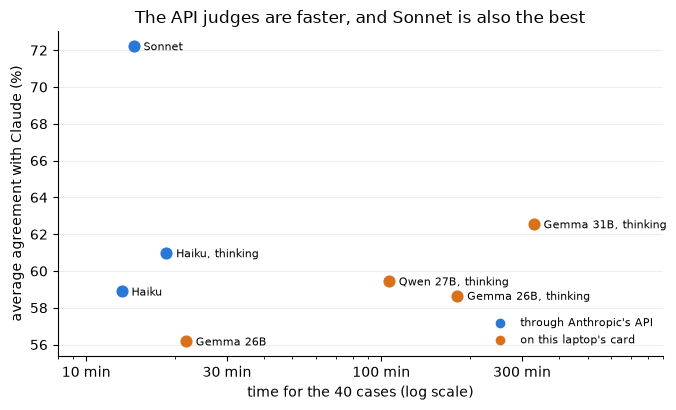

In [6]:
QUALITY = ["meaning = Claude (minute)", "stakes = Claude", "cold read finds the spot",
           "blind: reference both orders"]

fig, ax = plt.subplots(figsize=(7, 4.2))
for setup, name in JUDGES.items():
    quality = sum(share(every[name][q]) for q in QUALITY) / len(QUALITY)
    minutes = every[name]["minutes in all"]
    print(f"{name:20} {minutes:4.0f} min  {quality:.1f}%")
    on_api = setup.startswith("claude")
    ax.scatter(minutes, quality, s=60, color="#2a78d6" if on_api else "#d9711c", zorder=3)
    ax.annotate(name, (minutes, quality), xytext=(7, -3), textcoords="offset points", fontsize=8)

ax.set_xscale("log")
ax.set_xticks([10, 30, 100, 300])
ax.set_xticklabels(["10 min", "30 min", "100 min", "300 min"])
ax.set_xlim(8, 900)
ax.set_xlabel("time for the 40 cases (log scale)")
ax.set_ylabel("average agreement with Claude (%)")
ax.set_title("The API judges are faster, and Sonnet is also the best")
ax.scatter([], [], color="#2a78d6", label="through Anthropic's API")
ax.scatter([], [], color="#d9711c", label="on this laptop's card")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#eeeeee")
plt.tight_layout()
plt.show()

Sonnet stands apart, about 10 points above the rest. The other six fall between 56% and
63%, and with one case worth about 3 points, most of the gaps between them are within
what 40 cases can tell apart. Thinking helps the local models less than its cost suggests:
Gemma 31B with thinking took 15 times as long as Gemma 26B without, for about 6 points
more. Qwen 3.8 matches Haiku's quality at about eight times Haiku's time, which makes it
the choice for work that must stay on the laptop.

## 5. What this means, and its limits

- **A language model can do the first sort of the failure cases.** Every judge separates
  "same" from "changed" from "opposite" the way a careful reader does about three times in
  four, and none was fooled by the controls' texts.
- **Never show the judge the rule's answer.** Prompt 0.1 showed that a judge repeats a claim
  it is given, and Haiku still did so under 0.3, on the one question where the claim is
  shown.
- **Read a blind pick only when both orders agree.** Several judges pick whichever version
  comes first more often than not.
- **For the full run, Haiku with thinking on the meaning question** (about $9) is the
  affordable choice. Sonnet on the same question (about $55 batched) would be the stronger
  check.
- **Limits.** 40 cases is a small sample: one case is about 3 points in these percentages.
  The yardstick is Claude, not a listener. The API models take no temperature setting, so
  their answers may not repeat exactly. The cases were picked because an engine failed
  there, so these numbers are not an error rate for any engine.
- **Next:** listen to the five cases where the reference itself looks wrong (s05, s30,
  s34, s33, s32), try a prompt 0.4 (a longer list of changes, a better cold read), and add
  the Batch API to the script before any full run.